# Session 1: Why do we need compilers?

We train a small **multilayer perceptron (MLP)** to recognize handwritten digits,
then run the *same* inference computation in several ways:

1. **Naive Python loops**, the way you would write it in C
2. **NumPy**, a library of precompiled, hand-optimized kernels
3. **Numba**, a JIT compiler that turns the naive loops into machine code (via LLVM)
4. **Numba on hand-transformed loops**, showing what a compiler could do automatically

The performance gap between (1) and the others is what a compiler bridges.
In this lab you will build a compiler, `algeco`, that does this for linear algebra.

In [1]:
import time

import matplotlib.pyplot as plt
import numba
import numpy as np
import threadpoolctl
from sklearn.datasets import load_digits

# Our compiled code is single-threaded, so the NumPy (OpenBLAS) baseline is too.
threadpoolctl.threadpool_limits(1)

rng = np.random.default_rng(0)
print(f"numpy {np.__version__}, numba {numba.__version__}")

numpy 2.5.3, numba 0.68.0


## 1. The dataset

Each sample is an 8×8 grayscale image of a handwritten digit, flattened to a vector of 64 pixels.

train: (1400, 64), test: (397, 64)


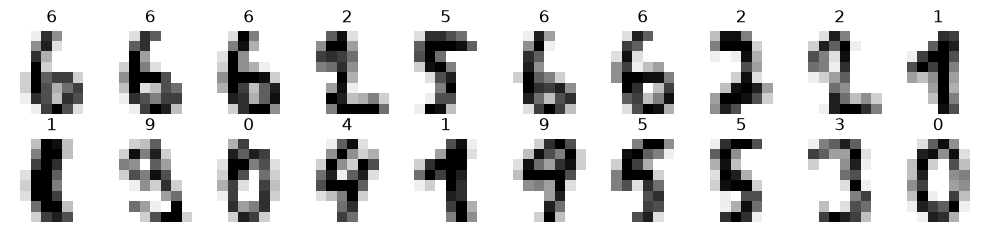

In [2]:
digits = load_digits()
X = (digits.data / 16.0).astype(np.float32)   # (n_samples, 64), values in [0, 1]
y = digits.target                              # (n_samples,), labels 0..9

perm = rng.permutation(len(X))
X, y = X[perm], y[perm]
n_train = 1400
X_train, y_train = X[:n_train], y[:n_train]
X_test, y_test = X[n_train:], y[n_train:]
print(f"train: {X_train.shape}, test: {X_test.shape}")

fig, axes = plt.subplots(2, 10, figsize=(10, 2.4))
for ax, img, label in zip(axes.flat, X_train, y_train):
    ax.imshow(img.reshape(8, 8), cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()

## 2. The model

A two-layer MLP:

$$
\mathrm{out} = \mathrm{ReLU}(x W_1 + b_1)\, W_2 + b_2
$$

with $x \in \mathbb{R}^{B \times 64}$, $W_1 \in \mathbb{R}^{64 \times H}$, $W_2 \in \mathbb{R}^{H \times 10}$.
The predicted digit is the index of the largest output (`argmax`).

The model only uses **three operators: matmul, add, and ReLU**. 

We train it with plain NumPy and gradient descent. You don't need to follow the
training code in detail; this course is about running the trained model fast.

In [3]:
D_IN, HIDDEN, D_OUT = 64, 256, 10

def init_params():
    w1 = rng.standard_normal((D_IN, HIDDEN), dtype=np.float32) * np.float32(np.sqrt(2 / D_IN))
    w2 = rng.standard_normal((HIDDEN, D_OUT), dtype=np.float32) * np.float32(np.sqrt(2 / HIDDEN))
    return [w1, np.zeros(HIDDEN, np.float32), w2, np.zeros(D_OUT, np.float32)]

def train(params, X, y, epochs=60, batch=64, lr=0.1):
    w1, b1, w2, b2 = params
    onehot = np.eye(D_OUT, dtype=np.float32)[y]
    for epoch in range(epochs):
        idx = rng.permutation(len(X))
        for s in range(0, len(X), batch):
            xb, tb = X[idx[s:s + batch]], onehot[idx[s:s + batch]]
            # forward
            z1 = xb @ w1 + b1
            h = np.maximum(z1, 0)
            out = h @ w2 + b2  # scores, then softmax
            p = np.exp(out - out.max(axis=1, keepdims=True))
            p /= p.sum(axis=1, keepdims=True)
            # backward (softmax + cross-entropy)
            g = (p - tb) / len(xb)
            gw2, gb2 = h.T @ g, g.sum(0)
            gh = (g @ w2.T) * (z1 > 0)
            gw1, gb1 = xb.T @ gh, gh.sum(0)
            for param, grad in zip((w1, b1, w2, b2), (gw1, gb1, gw2, gb2)):
                param -= lr * grad
    return params

t0 = time.perf_counter()
params = train(init_params(), X_train, y_train)
print(f"trained in {time.perf_counter() - t0:.1f} s")
w1, b1, w2, b2 = params
assert all(p.dtype == np.float32 for p in params)

trained in 0.4 s


## 3. Inference

From here on we only care about **inference**, the forward pass.

Each variant is a function that takes the trained weights and returns an `infer(x)` function.
Preparation happens once, then `infer` runs many times. This is how inference engines work, and it
lets a compiler specialize the code to the weights (see 3.4).

### 3.1 Naive loops

This is how you would write it in C: explicit loops, explicit intermediate buffers.

In [4]:
def mlp_naive(w1, b1, w2, b2):
  def infer(x):
    B, K = x.shape
    H = w1.shape[1]
    N = w2.shape[1]

    # layer 1
    # h = x @ w1
    h = np.empty((B, H), dtype=np.float32)
    for i in range(B):
        for j in range(H):
            acc = np.float32(0.0)
            for k in range(K):
                acc += x[i, k] * w1[k, j]
            h[i, j] = acc

    # h = h + b1
    for i in range(B):
        for j in range(H):
            h[i, j] = h[i, j] + b1[j]

    # h = relu(h) = max(h, 0)
    for i in range(B):
        for j in range(H):
            h[i, j] = max(h[i, j], np.float32(0.0))

    # layer 2
    # out = h @ b2
    out = np.empty((B, N), dtype=np.float32)
    for i in range(B):
        for j in range(N):
            out[i, j] = np.float32(0.0)
            for k in range(H):
                out[i, j] += h[i, k] * w2[k, j]

    # out = out + b2
    for i in range(B):
        for j in range(N):
            out[i, j] = out[i, j] + b2[j]
    return out
  return infer

### 3.2 NumPy

The same computation as a few calls into precompiled kernels. `@` dispatches to an optimized
BLAS library. In this environment that is OpenBLAS, restricted to a single thread so that the comparison with
our single-threaded code is fair.

In [5]:
def mlp_numpy(w1, b1, w2, b2):
  def infer(x):
    h = np.maximum(x @ w1 + b1, 0)
    return h @ w2 + b2
  return infer

### 3.3 Numba

`numba.njit` compiles the **unchanged** naive `infer` function to machine code the first time it is called. It does so by turning the python bytecode to LLVM IR and using LLVM to compile it.

In [6]:
def mlp_numba(w1, b1, w2, b2):
  return numba.njit(mlp_naive(w1, b1, w2, b2))

### 3.4 Numba, transformed by hand

The same algorithm after transformations that a compiler *could* apply, if it can prove them legal
or is given permission:

* **packing**: `w1` and `w2` are copied once into transposed form, so that the sum over `k` in both layers reads
  contiguous memory (the *dot form*: each output element is one dot product of two contiguous rows).
  Note that `np.transpose(w)` would not help: it only returns a *view* of the same memory with swapped strides.
  This replaces the loop interchange `i, j, k → i, k, j` that fixes the access pattern of `w1` without copying.
* **fusion**: bias and ReLU are applied right after a row of `h` is computed, with no separate passes over `h`.
  In both layers the bias is the starting value of the sum.
* **`fastmath=True`**: allows reordering floating-point sums. The dot form needs it: a reduction is a serial chain of additions, and
  without permission to reassociate, LLVM cannot vectorize it. Starting the sum from the bias instead of adding the bias
  afterwards is a reassociation too.
* **specialization to the weights**: the arrays and shapes captured by `infer` become *constants* in the compiled
  code. Packing happens once, before any inference, and LLVM knows every loop's trip count.

In [7]:
def mlp_numba_opt(w1, b1, w2, b2):
    """Pack the weights once and compile an inference function specialized to them."""
    w2t = np.ascontiguousarray(w2.T)
    w1t = np.ascontiguousarray(w1.T)
    K, H = w1.shape
    N = w2.shape[1]

    @numba.njit(fastmath=True)
    def infer(x):
        B = x.shape[0]
        h = np.empty(H, dtype=np.float32)
        out = np.empty((B, N), dtype=np.float32)
        for i in range(B):
            h[:] = b1
            for j in range(H):
                acc = h[j]
                for k in range(K):
                    acc += x[i, k] * w1t[j, k]
                h[j] = max(acc, np.float32(0.0))
            for j in range(N):
                acc = b2[j]
                for k in range(H):
                    acc += h[k] * w2t[j, k]
                out[i, j] = acc
        return out
    return infer


### Correctness first

Before we time anything, all variants must compute the same result and actually classify digits.

test accuracy: 97.7%


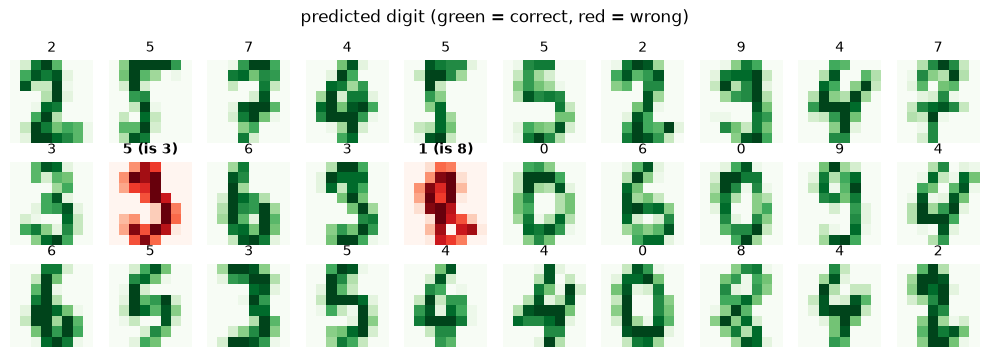

In [8]:
weights = (w1, b1, w2, b2)
ref = mlp_numpy(*weights)(X_test)
np.testing.assert_allclose(mlp_naive(*weights)(X_test[:50]), ref[:50], rtol=1e-4, atol=1e-4)
np.testing.assert_allclose(mlp_numba(*weights)(X_test), ref, rtol=1e-4, atol=1e-4)
np.testing.assert_allclose(mlp_numba_opt(*weights)(X_test), ref, rtol=1e-4, atol=1e-4)

pred = ref.argmax(axis=1)
print(f"test accuracy: {(pred == y_test).mean():.1%}")

fig, axes = plt.subplots(3, 10, figsize=(10, 3.6))
for ax, img, p, t in zip(axes.flat, X_test, pred, y_test, strict=False):
    correct = p == t
    ax.imshow(img.reshape(8, 8), cmap="Greens" if correct else "Reds")
    ax.set_title(f"{p}" if correct else f"{p} (is {t})", fontsize=10,
                 fontweight="normal" if correct else "bold")
    ax.axis("off")
plt.suptitle("predicted digit (green = correct, red = wrong)")
plt.tight_layout()

## 4. Timing

We report the **time per image**. Pure Python is so slow that we only run it on a small batch.

        naive Python:    4589.38 µs/image   (       1× faster than naive)
   Numba (same code):      32.07 µs/image   (     143× faster than naive)
 Numba (transformed):       1.02 µs/image   (    4491× faster than naive)
               NumPy:       0.66 µs/image   (    6962× faster than naive)


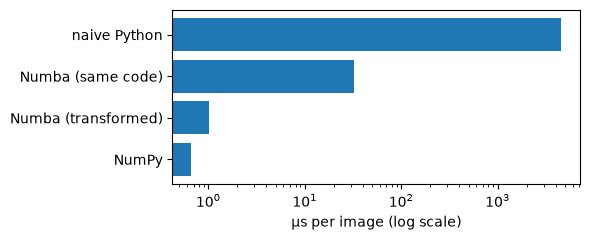

In [9]:
def bench(compile, x, repeat=5):
    infer = compile(w1, b1, w2, b2) # precompile with weights known
    infer(x)  # warm-up: JIT compilation (numba), BLAS thread start-up (numpy)
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        infer(x)
        best = min(best, time.perf_counter() - t0)
    return best / len(x)  # seconds per image

results = {
    "naive Python": bench(mlp_naive, X_test[:10], repeat=1),
    "Numba (same code)": bench(mlp_numba, X_test),
    "Numba (transformed)": bench(mlp_numba_opt, X_test),
    "NumPy": bench(mlp_numpy, X_test),
}
base = results["naive Python"]
for name, t in results.items():
    print(f"{name:>20}: {t * 1e6:10.2f} µs/image   ({base / t:8.0f}× faster than naive)")

fig, ax = plt.subplots(figsize=(6, 2.5))
ax.barh(list(results), [t * 1e6 for t in results.values()])
ax.set_xscale("log")
ax.set_xlabel("µs per image (log scale)")
ax.invert_yaxis()
plt.tight_layout()

**Questions**

1. Numba ran *exactly the same source code* as the naive version. Where does the speedup come from?
   What did the Python interpreter do for every single `acc += x[i, k] * w1[k, j]`?
2. NumPy needs no compiler at runtime. Why is it fast anyway? Who did the compilation work, and when?

## 5. Batch size matters

Batch size changes the picture. Each NumPy call (`@`, `+`, `maximum`) has a fixed overhead,
and each one writes a full intermediate array to memory.

batch      Numba (same code)   Numba (transformed)                 NumPy
    1               35.38 µs               1.73 µs               6.84 µs
    4               30.66 µs               1.25 µs               2.80 µs
   16               30.31 µs               1.08 µs               1.24 µs
   64               28.71 µs               1.05 µs               0.84 µs
  256               30.95 µs               1.01 µs               0.74 µs
 1024               32.35 µs               1.02 µs               0.69 µs
 4096               32.29 µs               1.05 µs               1.15 µs


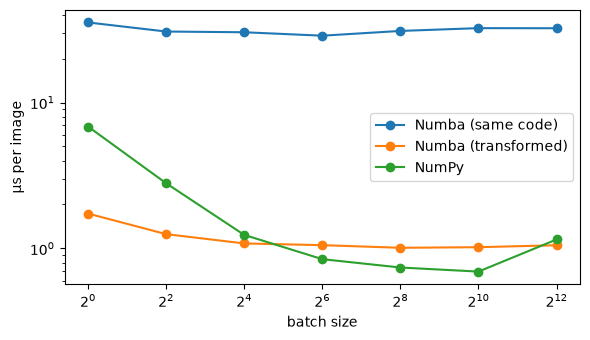

In [10]:
batch_sizes = [1, 4, 16, 64, 256, 1024, 4096]
X_big = rng.random((max(batch_sizes), D_IN), dtype=np.float32)

sweep = {"Numba (same code)": mlp_numba, "Numba (transformed)": mlp_numba_opt, "NumPy": mlp_numpy}
times = {name: [bench(fn, X_big[:b], repeat=20) * 1e6 for b in batch_sizes]
         for name, fn in sweep.items()}

fig, ax = plt.subplots(figsize=(6, 3.5))
for name, ts in times.items():
    ax.plot(batch_sizes, ts, marker="o", label=name)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("batch size")
ax.set_ylabel("µs per image")
ax.legend()
plt.tight_layout()

print("batch " + "".join(f"{n:>22}" for n in times))
for b, row in zip(batch_sizes, zip(*times.values(), strict=True), strict=True):
    print(f"{b:5d} " + "".join(f"{t:19.2f} µs" for t in row))

**Questions**

3. Which variant wins at batch size 1, and which at large batch sizes? Why?
4. Count the intermediate arrays NumPy creates for one call of `mlp_numpy`.
   Could a compiler that sees the *whole* expression `relu(x @ w1 + b1) @ w2 + b2`
   avoid creating some of them? (Spoiler: this is **operator fusion**, Task 2.)
5. Numba compiled our loops as written, and LLVM did not interchange them by itself. Look at `mlp_naive`:
   what would a compiler have to *prove* before applying the transformations of `mlp_numba_opt`?
   Think about what happens if `h` and `w1` were the same memory. Is it easier to prove if the
   compiler knows "this is `matmul`, then `add`, then `relu`"?
6. NumPy is still faster at large batch sizes. What else does an optimized BLAS do?
   (Spoiler: **tiling** for the cache hierarchy, Task 1, and **register tiling** + **vectorization**: a small
   block of the result stays in vector registers for the whole sum. That is Task 3.)

## 6. A look under the hood

Numba translates Python to **LLVM IR** and lets LLVM generate machine code. `algeco` will use the same
LLVM backend. The interesting work in this lab happens *before* LLVM, at a level where the compiler
still knows that it is looking at a matmul.

In [11]:
import collections
import re


def simd_instructions(fn):
    asm = fn.inspect_asm(fn.signatures[0])
    # x86: ymm/zmm registers (AVX), ARM: NEON vector registers
    return [l.strip() for l in asm.splitlines()
            if any(r in l for r in ("ymm", "zmm", ".4s", "fmla"))]


def float_ops(fn):
    """Count floating-point operations in the LLVM IR: vector (<8 x float>) vs. scalar."""
    ir = fn.inspect_llvm(fn.signatures[0])
    vector = re.findall(r"= (fadd|fmul|fcmp \w+|select)[^\n]*<\d+ x float>", ir)
    scalar = re.findall(r"= (fadd|fmul)(?: \w+)* float ", ir)
    return collections.Counter(vector), collections.Counter(scalar)


# Build the Numba-compiled inference functions (Python -> LLVM IR -> machine code).
# Numba compiles on the first call, so call each one once before inspecting it.
compiled = {
    "Numba(mlp_naive)": mlp_numba(*weights),
    "Numba(mlp_numba_opt)": mlp_numba_opt(*weights),
}
for label, fn in compiled.items():
    fn(X_test)
    vector, scalar = float_ops(fn)
    simd = simd_instructions(fn)
    print(f"{label}")
    print(f"  LLVM IR vector ops: {dict(vector)}")
    print(f"  LLVM IR scalar ops: {dict(scalar)}")
    print(f"  {len(simd)} SIMD instructions, e.g.")
    print("\n".join("    " + s for s in simd[:6]))
    print()

Numba(mlp_naive)
  LLVM IR vector ops: {'fadd': 32, 'fcmp olt': 32, 'select': 32}
  LLVM IR scalar ops: {'fadd': 119, 'fmul': 89}
  238 SIMD instructions, e.g.
    vmovaps	(%rcx), %ymm0
    vmovaps	(%r10), %ymm5
    vmovaps	(%r11), %ymm6
    vmovaps	(%rbx), %ymm7
    vmovaps	(%r14), %ymm8
    vmovaps	(%r12), %ymm9

Numba(mlp_numba_opt)
  LLVM IR vector ops: {'fmul': 336, 'fadd': 372}
  LLVM IR scalar ops: {'fadd': 12}
  839 SIMD instructions, e.g.
    vmovaps	(%rsi), %ymm11
    vmovaps	(%rsi), %ymm13
    vmovaps	(%rsi), %ymm15
    vmovaps	(%rdx), %ymm12
    vmovaps	(%rdx), %ymm14
    vmovaps	(%rcx), %ymm1



In `Numba(mlp_naive)`, LLVM vectorized only the **elementwise** loops: the bias add (`fadd <8 x float>`)
and the ReLU (`fcmp` + `select`). The matmul loops, where almost all the time goes, stay scalar: they
accumulate `acc += x[i, k] * w1[k, j]` as one long serial chain of `fadd float`. Floating-point addition
is not associative, so LLVM may not split the sum into independent vector lanes. That is exactly what
`fastmath=True` permits in `mlp_numba_opt`.

The instruction counts are much larger than you might expect. The weights and shapes are compile-time
constants, so LLVM knows every loop's length and unrolls the loops heavily. More instructions do not mean
slower code: what matters is how many are executed, and how many operate on full vectors.

**Question**

7. Vectorization (SIMD) is the topic of **Task 3**. LLVM vectorized some of our loops automatically.
   Which loops do you think it could vectorize, and which not? Why might a compiler that knows
   "this is a matmul" do better than LLVM, which only sees loops and memory accesses?